# Project Optimization: LV Grid with PV & BESS

## 1 — Installation

Run once. Version pins are required: pandapower conflicts with numpy ≥ 2.0.

In [1]:
# Installations & Imports
import pandapower as pp
import pandas as pd
import numpy as np
import gurobipy as gp

print("All modules imported successfully!")

All modules imported successfully!


## 2 — Parameters
**All tunable values live here.** Change these and re-run — nothing else needs editing.


In [2]:
# BASELINE parameters 
# The baseline is the reference FFOR against which all scenarios are compared.

# SoC parameters
SoC_init = 0.6     # initial state of charge (fraction 0–1)
SoC_min  = 0.4     # minimum allowed SoC  (baseline)
SoC_max  = 0.8     # maximum allowed SoC  (baseline)

# ── Other fixed parameters ────────────────────────────────────────────────
U_MIN = 0.9       # p.u. lower voltage bound
U_MAX = 1.10       # p.u. upper voltage bound
T     = 3      # number of hourly timesteps (set 8760 for full year)
h     = 1.0        # timestep duration in hours
t_start   = 11    # hour of day for FFOR computation (11 = solar peak)


# ── File paths f────────────────────────────────────────────────────────────
GRID_FILE  = '1001-1_0_3_grid.xlsx'
BESS_FILE  = 'BESS_allocation_LV.xlsx'
GEN_FILE  = 'LV_generation.csv'
INST_FILE = 'LV_P_installed.csv'
GRID_NAME  = '1001-1_0_3'


## 3 — Load Network from Excel

In [3]:
import numpy as np
import pandas as pd
import pandapower as pp
from IPython.display import display

pd.set_option('display.max_rows', 60)

# ── Read all sheets ──────────────────────────────────────────────────────
bus_df   = pd.read_excel(GRID_FILE, sheet_name='bus',      index_col=0)
load_df  = pd.read_excel(GRID_FILE, sheet_name='load',     index_col=0)
ext_df   = pd.read_excel(GRID_FILE, sheet_name='ext_grid', index_col=0)
line_df  = pd.read_excel(GRID_FILE, sheet_name='line',     index_col=0)
trafo_df = pd.read_excel(GRID_FILE, sheet_name='trafo',    index_col=0)
par_df   = pd.read_excel(GRID_FILE, sheet_name='parameters')

f_hz   = float(par_df.loc[0, 'f_hz'])
sn_mva = float(par_df.loc[0, 'sn_mva'])
net = pp.create_empty_network(name=GRID_NAME, f_hz=f_hz, sn_mva=sn_mva)

# 1) Buses
for old_idx, row in bus_df.iterrows():
    pp.create_bus(
        net, vn_kv=float(row['vn_kv']),
        name=row['name'] if pd.notna(row['name']) else None,
    )

# 2) External grid (PCC / slack bus)
for _, row in ext_df.iterrows():
    pp.create_ext_grid(
        net,
        bus=int(row['bus']),
        vm_pu=float(row['vm_pu'])           if 'vm_pu'        in row and pd.notna(row['vm_pu'])        else 1.0,
        va_degree=float(row['va_degree'])   if 'va_degree'    in row and pd.notna(row['va_degree'])    else 0.0,
    )

# 3) Loads
for _, row in load_df.iterrows():
    pp.create_load(
        net, 
        bus=int(row['bus']),
        p_mw=float(row['p_mw']), q_mvar=float(row['q_mvar']),
        name=row['name']                   if 'name'       in row and pd.notna(row['name'])       else None,
    )

# 4) Lines
for _, row in line_df.iterrows():
    pp.create_line_from_parameters(
        net,
        from_bus=int(row['from_bus']),
        to_bus=int(row['to_bus']),
        length_km=float(row['length_km']),
        r_ohm_per_km=float(row['r_ohm_per_km']),
        x_ohm_per_km=float(row['x_ohm_per_km']),
        c_nf_per_km=float(row['c_nf_per_km']),
        max_i_ka=float(row['max_i_ka']),
        g_us_per_km=float(row['g_us_per_km'])  if 'g_us_per_km' in row and pd.notna(row['g_us_per_km']) else 0.0,
        parallel=int(row['parallel'])          if 'parallel'    in row and pd.notna(row['parallel'])    else 1,
        name=row['name']                       if 'name'        in row and pd.notna(row['name'])        else None,
    )

# 5) Transformer — full parameter set including tap_side & tap_phase_shifter
for _, row in trafo_df.iterrows():
    pp.create_transformer_from_parameters(
        net,
        hv_bus=int(row['hv_bus']),
        lv_bus=int(row['lv_bus']),
        sn_mva=float(row['sn_mva']),         vn_hv_kv=float(row['vn_hv_kv']),
        vn_lv_kv=float(row['vn_lv_kv']),     vk_percent=float(row['vk_percent']),
        vkr_percent=float(row['vkr_percent']),pfe_kw=float(row['pfe_kw']),
        i0_percent=float(row['i0_percent']),
        tap_side=row['tap_side']                        if 'tap_side'         in row and pd.notna(row['tap_side'])         else None,
        tap_neutral=int(row['tap_neutral'])             if 'tap_neutral'      in row and pd.notna(row['tap_neutral'])      else 0,
        tap_min=int(row['tap_min'])                     if 'tap_min'          in row and pd.notna(row['tap_min'])          else 0,
        tap_max=int(row['tap_max'])                     if 'tap_max'          in row and pd.notna(row['tap_max'])          else 0,
        tap_step_percent=float(row['tap_step_percent']) if 'tap_step_percent' in row and pd.notna(row['tap_step_percent']) else 0.0,
        tap_pos=int(row['tap_pos'])                     if 'tap_pos'          in row and pd.notna(row['tap_pos'])          else 0,
        name=row['name']                                if 'name'             in row and pd.notna(row['name'])             else None,
    )

#Base-case power flow
pp.runpp(net, voltage_depend_loads=False)

## 4 — Build Linearised Power-Flow Matrices (`b_lin`, `A_lin`)

In [4]:
# Build mapping: OSM node ID → pandapower bus index
# Bus names look like: 'bus_LV_1001-1_0_3_node_141'
# Needed later because in the BESS file, we have a node for each battery "LV_osmid" so need to atch it to a bus
osmid_to_bus = {}
for pp_bus_idx, row in bus_df.iterrows():
    node_num = int(row['name'].split('_node_')[-1])
    osmid_to_bus[node_num] = int(pp_bus_idx)

In [5]:
n_bus    = len(net.bus)
n_loads = len(net.load)
load_buses = list(net.load['bus'].values)
pcc_idx = int(ext_df['bus'].iloc[0])

# ── Base case PCC power ───────────────────────────────────────────────────
P_pcc_base = float(net.res_ext_grid['p_mw'].iloc[0])   * 1000.0  # kW
Q_pcc_base = float(net.res_ext_grid['q_mvar'].iloc[0]) * 1000.0  # kvar

print(f'\nPCC base case:')
print(f'  P_pcc_base = {P_pcc_base:.3f} kW')
print(f'  Q_pcc_base = {Q_pcc_base:.3f} kvar')
print(f'  V_pcc      = {net.res_bus.loc[pcc_idx, "vm_pu"]:.5f} p.u.')
print(f'  theta_pcc  = {net.res_bus.loc[pcc_idx, "va_degree"]:.5f} deg')

# Extract Jacobian and build correct bus order 
try:
    internal = net['_ppc']['internal']
    J = internal['J'].toarray()
    A_lin = -J

    
    pq_ppc   = list(map(int, internal['pq']))   # PQ-type buses (load buses)
    pvpq_ppc = pq_ppc                 
    pf_buses_P = pq_ppc
    pf_buses_Q = pf_buses_P

    P_base     = - net.res_bus.loc[pf_buses_P, 'p_mw'].values
    Q_base     = - net.res_bus.loc[pf_buses_Q, 'q_mvar'].values
    theta_base = np.deg2rad(net.res_bus.loc[pf_buses_P, 'va_degree'].values)
    dU_base    = net.res_bus.loc[pf_buses_Q, 'vm_pu'].values - 1.0

    x_base = np.concatenate([theta_base, dU_base])
    y_base = np.concatenate([P_base, Q_base])

    b_lin = y_base - A_lin @ x_base

    print(f'Jacobian extracted successfully')

except Exception as e:
    print(f'WARNING: Jacobian unavailable ({e}). Using identity fallback.')

    pf_buses = [b for b in net.bus.index if int(b) != int(pcc_idx)]

    n = 2 * len(pf_buses)
    A_lin = np.eye(n)
    b_lin = np.zeros(n)



PCC base case:
  P_pcc_base = 175.542 kW
  Q_pcc_base = 43.995 kvar
  V_pcc      = 1.00000 p.u.
  theta_pcc  = 0.00000 deg
Jacobian extracted successfully


## 5 — Load BESS Data & PV Timeseries

In [6]:
# NEW PV version (use PV from same Data Set as BESS, for data consistency which also provides insatlled capacity per PV node, not provided
# by the EU Commision source)

# Load actual per-node PV generation from dataset (2030 scenario, Jan 15)
# LV_generation columns: LV_grid, LV_osmid, 01-15 00:00, 01-15 01:00, ...
df_inst = pd.read_csv(INST_FILE)

chunks = []
for chunk in pd.read_csv(GEN_FILE, chunksize=10000, dtype={'LV_grid': str}):
    match = chunk[chunk['LV_grid'] == GRID_NAME]
    if len(match) > 0:
        chunks.append(match)

df_gen = pd.concat(chunks).reset_index(drop=True)

# Filter for our grid
grid_gen  = df_gen[df_gen['LV_grid']  == GRID_NAME].copy()
grid_inst = df_inst[df_inst['LV_grid'] == GRID_NAME].copy()

# Map osmid to pandapower bus index
grid_gen['bus']  = grid_gen['LV_osmid'].apply(
    lambda x: osmid_to_bus.get(int(x), None))
grid_inst['bus'] = grid_inst['LV_osmid'].apply(
    lambda x: osmid_to_bus.get(int(x), None))

# Drop nodes not found in bus map (safety check)
grid_gen  = grid_gen.dropna(subset=['bus'])
grid_inst = grid_inst.dropna(subset=['bus'])
grid_gen['bus']  = grid_gen['bus'].astype(int)
grid_inst['bus'] = grid_inst['bus'].astype(int)

# build PV index set V, one entry per PV node
n_pv       = len(grid_gen)
V          = list(range(n_pv))
pv_bus_of_v = {v: int(grid_gen.iloc[v]['bus'])           for v in V}
pv_kWp_of_v = {v: float(grid_inst.iloc[v]['P_installed_kW']) for v in V}

# Generation timeseries columns (skip LV_grid, LV_osmid, bus = first 3 cols)
time_cols = [c for c in grid_gen.columns if c not in ['LV_grid','LV_osmid','bus']]
# Take T timesteps starting from t_start (set in parameters cell)
selected_cols = time_cols[t_start : t_start + T]

# P_pv_set[v, t] = actual generation at node v, hour t  (kW)
# Already scaled by installed capacity in the dataset — > no multiplication needed
P_pv_set = np.zeros((n_pv, T))
for v in V:
    P_pv_set[v, :] = grid_gen.iloc[v][selected_cols].values.astype(float)

In [7]:
import openpyxl

# ── BESS data from allocation file ─────────────────────────────────────
wb_bess   = openpyxl.load_workbook(BESS_FILE, read_only=True)
ws_bess   = wb_bess.active
rows_bess = [r[0] for r in ws_bess.iter_rows(values_only=True) if r[0]]

bess_list = []
for r in rows_bess[1:]:
    parts = r.split(',')
    if parts[0] == GRID_NAME:
        # parts: [LV_grid, LV_osmid, Battery_capacity_kWh, Nominal_power_kW, eta_c, eta_d]
        osmid = int(parts[1])
        bess_list.append({
            'osmid': osmid,
            'bus':   osmid_to_bus[osmid],
            'C_s':   float(parts[2]),
            'P_nom': float(parts[3]),
        })

S             = list(range(len(bess_list)))        # [0, 1, 2] bcs 3 BESS
bess_bus = {s: bess_list[s]['bus']  for s in S}
C_s      = {s: bess_list[s]['C_s']  for s in S}
P_nom    = {s: bess_list[s]['P_nom'] for s in S}

In [8]:

# Extend PV fleet to 20 using real data from other Swiss grids

TARGET_N_PV  = 20
RNG_SEED_PV  = 43

if len(V) >= TARGET_N_PV:
    print(f'PV already at target ({len(V)})')
else:
    rng_pv          = np.random.default_rng(RNG_SEED_PV)
    original_pv_ids = list(V)

    # ── Sampling pool from own 10 PVs ──
    pool_kWp     = list(pv_kWp_of_v.values())
    pool_profiles = P_pv_set.copy()  # shape (10, T)

    # ── Find available load buses without PV ──
    used_pv_buses   = set(pv_bus_of_v.values())
    available_buses = [b for b in load_buses if b not in used_pv_buses]

    n_new_pv = TARGET_N_PV - len(V)

    if n_new_pv > len(available_buses):
        raise ValueError(f'Not enough free load buses ({len(available_buses)}) to place {n_new_pv} PV')

    # ── Sample buses and pool entries ──
    new_pv_buses = rng_pv.choice(available_buses, size=n_new_pv, replace=False)
    picks        = rng_pv.integers(len(pool_kWp),  size=n_new_pv)

    # ── Add new PV nodes ──
    new_profiles = np.zeros((n_new_pv, T))
    for i, (new_bus, pick) in enumerate(zip(new_pv_buses, picks)):
        v_new = len(V)
        V.append(v_new)
        pv_bus_of_v[v_new] = int(new_bus)
        pv_kWp_of_v[v_new] = float(pool_kWp[pick])
        new_profiles[i]    = pool_profiles[pick]

    P_pv_set = np.vstack([P_pv_set, new_profiles])

In [9]:
TARGET_N_BESS = 6
RNG_SEED_BESS = 42

if len(S) >= TARGET_N_BESS:
    print(f'BESS already at target ({len(S)})')
else:
    rng = np.random.default_rng(RNG_SEED_BESS)
    original_ids = list(S)

    # ── Find PV nodes without existing BESS ──
    bess_buses      = set(bess_bus.values())
    pv_without_bess = [v for v in V if pv_bus_of_v[v] not in bess_buses]

    n_new = TARGET_N_BESS - len(S)

    if n_new > len(pv_without_bess):
        raise ValueError(f'Not enough PV nodes without BESS ({len(pv_without_bess)}) to place {n_new} BESS')

    # ── Randomly select PV nodes to host new BESS ──
    new_bess_hosts = rng.choice(pv_without_bess, size=n_new, replace=False)

    for v in new_bess_hosts:
        s_new           = len(S)
        S.append(s_new)
        bess_bus[s_new] = pv_bus_of_v[v]        # same bus as PV 
        P_nom[s_new]    = pv_kWp_of_v[v]        # match PV power 
        C_s[s_new]      = pv_kWp_of_v[v] * 2.5  # 2.5h storage duration 

## 6 — FFOR Computation: full optimisation model

In [10]:
import gurobipy as gp
from gurobipy import GRB
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

print('Initialising Gurobi model (FFOR — Doppelschwand, full constraints)...')

# ── Sets ────────────────────────────────────────────────────────────────
N    = list(range(n_bus))          # all buses
L    = list(range(len(net.line)))  # all lines
TIME = list(range(T))              # timesteps 0 … T-1

# ── Base-case PCC power ─────────────────────────────────────────────────
P_pcc_base = float(net.res_ext_grid['p_mw'].iloc[0]) * 1000.0
Q_pcc_base = float(net.res_ext_grid['q_mvar'].iloc[0]) * 1000.0

print(f'Base case PCC: P={P_pcc_base:.3f} kW | Q={Q_pcc_base:.3f} kvar')
# print(f'BESS bus used in optimisation: {bess_bus}')
print(f'BESS buses: {bess_bus}')
print(f'PV nodes: {len(V)} | BESS units: {len(S)}')

# ── Helper: linear diamond approximation of apparent-power limits ───────
# |P| + |Q| <= S
def add_diamond_limit(m, P, Q, Smax, name):
    m.addConstr( P + Q <= Smax, name=f'{name}_pp')
    m.addConstr( P - Q <= Smax, name=f'{name}_pm')
    m.addConstr(-P + Q <= Smax, name=f'{name}_mp')
    m.addConstr(-P - Q <= Smax, name=f'{name}_mm')

# ── Line thermal limits ─────────────────────────────────────────────────
# To avoid infeasibility caused by inconsistent data, the limit is never
# smaller than the base-case apparent power on that line.
line_smax = {}

for ell in L:
    row = net.line.iloc[ell]

    P0 = abs(float(net.res_line['p_from_mw'].iloc[ell]) * 1000.0)
    Q0 = abs(float(net.res_line['q_from_mvar'].iloc[ell]) * 1000.0)
    S0 = np.sqrt(P0**2 + Q0**2)

    vn_kv = float(net.bus.vn_kv.loc[int(row.from_bus)])
    S_rating = np.sqrt(3) * vn_kv * float(row.max_i_ka) * 1000.0
    line_smax[ell] = S_rating

# ── Linear branch coefficients, base-aware ──────────────────────────────
line_coeff = {}

theta_base_all = np.deg2rad(net.res_bus['va_degree'].values)
dU_base_all    = net.res_bus['vm_pu'].values - 1.0

for ell in L:
    row = net.line.iloc[ell]

    fr = int(row.from_bus)
    to = int(row.to_bus)

    r = float(row.r_ohm_per_km) * float(row.length_km)
    x = float(row.x_ohm_per_km) * float(row.length_km)
    z2 = max(r*r + x*x, 1e-12)

    vn_kv = float(net.bus.vn_kv.loc[fr])
    v2 = (vn_kv * 1000.0) ** 2

    # kW/kvar per p.u./rad approximation
    g_kw = v2 * r / z2 / 1000.0
    b_kw = v2 * x / z2 / 1000.0

    P0 = float(net.res_line['p_from_mw'].iloc[ell]) * 1000.0
    Q0 = float(net.res_line['q_from_mvar'].iloc[ell]) * 1000.0

    dU0_diff    = dU_base_all[fr] - dU_base_all[to]
    theta0_diff = theta_base_all[fr] - theta_base_all[to]

    line_coeff[ell] = {
        'from': fr,
        'to': to,
        'g_kw': g_kw,
        'b_kw': b_kw,
        'P0': P0,
        'Q0': Q0,
        'dU0_diff': dU0_diff,
        'theta0_diff': theta0_diff,
    }


def solve_ffor_direction(alpha, beta, silent=True):
    """
    Solve one LP in direction (alpha, beta).
    Returns (P_flex*, Q_flex*) or None if infeasible/unbounded.
    Objective: min alpha*P_flex + beta*Q_flex.
    """

    m = gp.Model()

    m.setParam('OutputFlag', 0 if silent else 1)
    m.setParam('TimeLimit', 30)

    # Important for debugging INF_OR_UNBD
    m.setParam('DualReductions', 0)
    m.setParam('InfUnbdInfo', 1)
    m.setParam('NumericFocus', 2)

    # ── Variables ────────────────────────────────────────────────────────
    # BESS
    Pb = m.addVars(S, TIME,
               lb={(s,t): -P_nom[s] for s in S for t in TIME},
               ub={(s,t):  P_nom[s] for s in S for t in TIME},
               name='Pb')
    Qb = m.addVars(S, TIME,
                lb={(s,t): -P_nom[s] for s in S for t in TIME},
                ub={(s,t):  P_nom[s] for s in S for t in TIME},
                name='Qb')
    
    SoC_var = m.addVars(
        S, TIME,
        lb=SoC_min,
        ub=SoC_max,
        name='SoC'
    )

    # PV
    Ppv = m.addVars(
        V, TIME,
        lb=0.0,
        name='Ppv'
    )

    Qpv = m.addVars(
        V, TIME,
        lb=-GRB.INFINITY,
        ub=GRB.INFINITY,
        name='Qpv'
    )

    # -------

    P_flex = m.addVars(
        TIME,
        lb=-GRB.INFINITY,
        ub=GRB.INFINITY,
        name='P_pcc_flex'
    )

    Q_flex = m.addVars(
        TIME,
        lb=-GRB.INFINITY,
        ub=GRB.INFINITY,
        name='Q_pcc_flex'
    )

    theta = m.addVars(
        N, TIME,
        lb=-GRB.INFINITY,
        ub=GRB.INFINITY,
        name='theta'
    )

    dU = m.addVars(
        N, TIME,
        lb=U_MIN - 1.0,
        ub=U_MAX - 1.0,
        name='dU'
    )

    Pbus = m.addVars(
        N, TIME,
        lb=-GRB.INFINITY,
        ub=GRB.INFINITY,
        name='Pbus'
    )

    Qbus = m.addVars(
        N, TIME,
        lb=-GRB.INFINITY,
        ub=GRB.INFINITY,
        name='Qbus'
    )

    Pline = m.addVars(
        L, TIME,
        lb=-GRB.INFINITY,
        ub=GRB.INFINITY,
        name='Pline'
    )

    Qline = m.addVars(
        L, TIME,
        lb=-GRB.INFINITY,
        ub=GRB.INFINITY,
        name='Qline'
    )

    # ── Objective ────────────────────────────────────────────────────────
    m.setObjective(alpha * P_flex[0] + beta * Q_flex[0], GRB.MINIMIZE)

    # Battery constraints 
    for s in S:
        m.addConstr(
            SoC_var[s, 0] == SoC_init,
            name=f'C01_SoC_init[{s}]'
        )

        for t in TIME:
            add_diamond_limit(m, Pb[s,t], Qb[s,t], P_nom[s], f'C04_BESS_power[{s},{t}]')

        for t in range(T - 1):
            m.addConstr(
                SoC_var[s, t+1] == SoC_var[s, t] - (h / C_s[s]) * Pb[s, t],
                name=f'C02_SoC_dyn[{s},{t}]'
            )

    # PV constraints
    for v in V:
        for t in TIME:
            S_pv = float(P_pv_set[v, t])

            add_diamond_limit(
                m,
                Ppv[v, t],
                Qpv[v, t],
                S_pv,
                f'C07_PV_power[{v},{t}]'
            )

            m.addConstr(Ppv[v, t] <= S_pv, name=f'C08_PV_P_ub[{v},{t}]')
            m.addConstr(Ppv[v, t] >= 0.0,  name=f'C08_PV_P_lb[{v},{t}]')

            m.addConstr(Qpv[v, t] <=  S_pv, name=f'C09_PV_Q_ub[{v},{t}]')
            m.addConstr(Qpv[v, t] >= -S_pv, name=f'C09_PV_Q_lb[{v},{t}]')

    # Node injection DEVIATION constraints 
    # Pbus/Qbus are now deviations from the base case.
    # Positive PV/BESS injection reduces net consumption, so deviation = - device injection.
    
    for n in N:
        for t in TIME:
            P_dev = (
                gp.quicksum(Pb[s, t] for s in S if bess_bus[s] == n)
                + gp.quicksum(Ppv[v, t] for v in V if pv_bus_of_v[v] == n)
            )
    
            Q_dev = (
                gp.quicksum(Qb[s, t] for s in S if bess_bus[s] == n)
                + gp.quicksum(Qpv[v, t] for v in V if pv_bus_of_v[v] == n)
            )
    
            m.addConstr(
                Pbus[n, t] == -P_dev,
                name=f'C10_node_P_dev[{n},{t}]'
            )
    
            m.addConstr(
                Qbus[n, t] == -Q_dev,
                name=f'C11_node_Q_dev[{n},{t}]'
            )
    
    
    # Linearised power-flow DEVIATION model 
    # Use Jacobian as: ΔP, ΔQ = A_lin @ Δx
    
    for t in TIME:
        x_dev_terms = (
            [theta[n, t] - theta_base_all[n] for n in pf_buses_P]
            + [dU[n, t] - dU_base_all[n] for n in pf_buses_Q]
        )
    
        n_pf = len(pf_buses_P)
    
        for idx, n in enumerate(pf_buses_P):
            exprP = 0
            exprQ = 0
    
            for k in range(2 * n_pf):
                aP = float(A_lin[idx, k])
                aQ = float(A_lin[n_pf + idx, k])
    
                if abs(aP) > 1e-12:
                    exprP += aP * x_dev_terms[k]
    
                if abs(aQ) > 1e-12:
                    exprQ += aQ * x_dev_terms[k]
    
            m.addConstr(
                Pbus[n, t] / 1000.0 == exprP,
                name=f'C12_lin_P_dev[{n},{t}]'
            )
    
            m.addConstr(
                Qbus[n, t] / 1000.0 == exprQ,
                name=f'C12_lin_Q_dev[{n},{t}]'
            )

    # Voltage and slack-bus constraints 
    
        # Slack bus fixed at base-case value, not necessarily exactly 0
        m.addConstr(
            theta[pcc_idx, t] == theta_base_all[pcc_idx],
            name=f'C17_slack_theta[{t}]'
        )
    
        m.addConstr(
            dU[pcc_idx, t] == dU_base_all[pcc_idx],
            name=f'C18_slack_U[{t}]'
        )

    # Line-flow model and line limits 
    for ell in L:
        data = line_coeff[ell]

        fr = data['from']
        to = data['to']

        g_kw = data['g_kw']
        b_kw = data['b_kw']

        P0 = data['P0']
        Q0 = data['Q0']

        dU0_diff    = data['dU0_diff']
        theta0_diff = data['theta0_diff']

        smax = line_smax[ell]

        for t in TIME:
            dU_diff = dU[fr, t] - dU[to, t]
            th_diff = theta[fr, t] - theta[to, t]

            m.addConstr(
                Pline[ell, t]
                == P0
                + g_kw * (dU_diff - dU0_diff)
                + b_kw * (th_diff - theta0_diff),
                name=f'C13_line_P_model[{ell},{t}]'
            )

            m.addConstr(
                Qline[ell, t]
                == Q0
                - b_kw * (dU_diff - dU0_diff)
                + g_kw * (th_diff - theta0_diff),
                name=f'C14_line_Q_model[{ell},{t}]'
            )

            add_diamond_limit(
                m,
                Pline[ell, t],
                Qline[ell, t],
                smax,
                f'C15_line_limit[{ell},{t}]'
            )

    # PCC flex definition and sustained duration 
    for t in TIME:
        P_total_devices_t = (
            gp.quicksum(Pb[s, t] for s in S)
            + gp.quicksum(Ppv[v, t] for v in V)
        )

        Q_total_devices_t = (
            gp.quicksum(Qb[s, t] for s in S)
            + gp.quicksum(Qpv[v, t] for v in V)
        )

        m.addConstr(
            P_flex[t] == -P_total_devices_t,
            name=f'def_P_pcc_flex[{t}]'
        )

        m.addConstr(
            Q_flex[t] == -Q_total_devices_t,
            name=f'def_Q_pcc_flex[{t}]'
        )

    for t in range(T - 1):
        m.addConstr(
            P_flex[t] == P_flex[t + 1],
            name=f'C19_sustained_P[{t}]'
        )

        m.addConstr(
            Q_flex[t] == Q_flex[t + 1],
            name=f'C20_sustained_Q[{t}]'
        )

    # Solve
    m.optimize()

    if m.Status == GRB.OPTIMAL:

        duals = {
            c.ConstrName: c.Pi
            for c in m.getConstrs()
            if abs(c.Pi) > 1e-6
        }

        return (P_flex[0].X, Q_flex[0].X), duals

    if not silent:
        print(f'\nNo optimum for direction alpha={alpha}, beta={beta}.')
        print(f'Gurobi status = {m.Status}')

        if m.Status == GRB.INFEASIBLE:
            print('\nModel is INFEASIBLE. Computing IIS...')
            m.computeIIS()

            print('\nIIS constraints:')
            for c in m.getConstrs():
                if c.IISConstr:
                    print('  ', c.ConstrName)

            print('\nIIS variable bounds:')
            for v in m.getVars():
                if v.IISLB:
                    print('  LB:', v.VarName, v.LB)
                if v.IISUB:
                    print('  UB:', v.VarName, v.UB)

        elif m.Status == GRB.UNBOUNDED:
            print('\nModel is UNBOUNDED.')
            print('Check variables with infinite bounds and objective direction.')

        elif m.Status == GRB.INF_OR_UNBD:
            print('\nModel is infeasible or unbounded.')
            print('DualReductions=0 should normally separate the two cases.')

    return None

Initialising Gurobi model (FFOR — Doppelschwand, full constraints)...
Base case PCC: P=175.542 kW | Q=43.995 kvar
BESS buses: {0: 16, 1: 33, 2: 32, 3: 41, 4: 62, 5: 36}
PV nodes: 20 | BESS units: 6


In [11]:
# ── Algorithm 1: Iterative FFOR boundary refinement ─────────────────────
# Input: tolerance epsilon_tol (area units: kW * kvar)

epsilon_tol = 0.01


def triangle_area(p1, p2, p3):
    """Area of triangle (p1, p2, p3)."""
    return 0.5 * abs(
        (p2[0] - p1[0]) * (p3[1] - p1[1])
        - (p3[0] - p1[0]) * (p2[1] - p1[1])
    )


def unique_vertices(points, tol=1e-6):
    """Remove duplicate vertices returned by different directions."""
    out = []

    for p in points:
        if p is None:
            continue

        duplicate = False

        for q in out:
            if np.hypot(p[0] - q[0], p[1] - q[1]) <= tol:
                duplicate = True
                break

        if not duplicate:
            out.append(p)

    return out


def sort_vertices_ccw(points):
    """Sort vertices counter-clockwise."""
    if len(points) == 0:
        return []

    cx = np.mean([p[0] for p in points])
    cy = np.mean([p[1] for p in points])

    return sorted(
        points,
        key=lambda p: np.arctan2(p[1] - cy, p[0] - cx)
    )


def edge_normal_direction(vi, vj):
    """
    Returns outward normal direction for a CCW polygon.

    Since solve_ffor_direction MINIMISES alpha*P + beta*Q,
    we use the outward normal directly.
    """

    dx = vj[0] - vi[0]
    dy = vj[1] - vi[1]

    norm = np.hypot(dx, dy)

    if norm < 1e-10:
        return (1.0, 0.0)

    # outward normal for CCW ordering
    return (dy / norm, -dx / norm)


# ── Step 1: Initialise with 4 extreme vertices ───────────────────────────
v1, _ = solve_ffor_direction(+1,  0)   # min P
v2, _ = solve_ffor_direction( 0, +1)   # min Q
v3, _ = solve_ffor_direction(-1,  0)   # max P
v4, _ = solve_ffor_direction( 0, -1)   # max Q


init_verts = unique_vertices([v1, v2, v3, v4])
init_verts = sort_vertices_ccw(init_verts)

if len(init_verts) < 3:
    raise RuntimeError(
        '\nFFOR polygon cannot be built because fewer than 3 initial vertices were found.\n'
        f'Vertices found: {init_verts}\n\n'
        'This means the optimisation model in solve_ffor_direction is still infeasible or unbounded.\n'
        'Run the previous cell and read the IIS printed by Gurobi.'
    )


# ── Step 2: Create initial polygon ───────────────────────────────────────
vertices = list(init_verts)

n = len(vertices)
edges = deque([(i, (i + 1) % n) for i in range(n)])

solve_count = 4
iter_count  = 0


# ── Step 3: Iterative refinement ─────────────────────────────────────────
while edges:
    iter_count += 1

    i, j = edges.popleft()

    vi = vertices[i]
    vj = vertices[j]

    alpha, beta = edge_normal_direction(vi, vj)

    result, _ = solve_ffor_direction(alpha, beta, silent=True)
    solve_count += 1

    if result is None:
        print(
            f'Warning: solve failed for edge ({i},{j}) '
            f'with alpha={alpha:.4f}, beta={beta:.4f}'
        )
        continue

    v_new = result

    delta_A = triangle_area(vi, v_new, vj)

    if delta_A > epsilon_tol:

        # avoid duplicate vertices
        duplicate = any(
            np.hypot(v_new[0]-v[0], v_new[1]-v[1]) < 1e-6
            for v in vertices
        )
        
        if duplicate:
            continue
        
        new_idx = len(vertices)
        vertices.append(v_new)

        edges.append((i, new_idx))
        edges.append((new_idx, j))

    if iter_count % 20 == 0:
        print(
            f'  iter {iter_count}: '
            f'{len(vertices)} vertices | '
            f'{len(edges)} edges remaining | '
            f'{solve_count} LP solves total'
        )

# ── Step 4: Sort vertices CCW and compute area ───────────────────────────
vertices_sorted = sort_vertices_ccw(vertices)

if len(vertices_sorted) < 3:
    raise RuntimeError(
        f'Only {len(vertices_sorted)} vertices after refinement. '
        'Cannot build FFOR polygon.'
    )

ffor_P = np.array(
    [v[0] for v in vertices_sorted] + [vertices_sorted[0][0]]
)

ffor_Q = np.array(
    [v[1] for v in vertices_sorted] + [vertices_sorted[0][1]]
)

ffor_area = 0.5 * abs(
    np.dot(ffor_P[:-1], ffor_Q[1:])
    - np.dot(ffor_Q[:-1], ffor_P[1:])
)

print(f'FFOR area: {ffor_area:.4f} kW·kvar')
print(f'P range:   [{ffor_P.min():.3f}, {ffor_P.max():.3f}] kW')
print(f'Q range:   [{ffor_Q.min():.3f}, {ffor_Q.max():.3f}] kvar')

Set parameter Username
Set parameter LicenseID to value 2816950
Academic license - for non-commercial use only - expires 2027-05-01
FFOR area: 10032.2501 kW·kvar
P range:   [-56.737, 15.411] kW
Q range:   [-93.480, 93.480] kvar


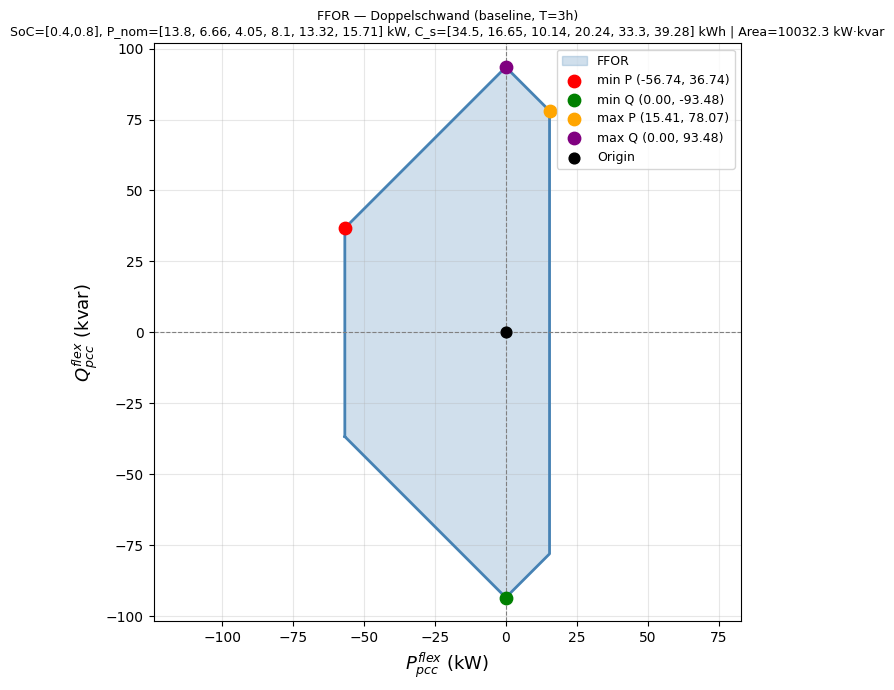

Saved: FFOR_baseline.png  |  7 vertices  |  14 LP solves


In [12]:
# Plot FFOR 
fig, ax = plt.subplots(figsize=(7, 7))

ax.fill(ffor_P, ffor_Q, alpha=0.25, color='steelblue', label='FFOR')
ax.plot(ffor_P, ffor_Q, color='steelblue', lw=2)

# Mark the 4 initial extreme vertices
labels = ['min P', 'min Q', 'max P', 'max Q']
colors = ['red', 'green', 'orange', 'purple']
for v, lbl, col in zip([v1,v2,v3,v4], labels, colors):
    if v is not None:
        ax.scatter(*v, color=col, zorder=5, s=80, label=f'{lbl} ({v[0]:.2f}, {v[1]:.2f})')

ax.scatter(0, 0, color='black', zorder=5, s=60, label='Origin')
ax.axhline(0, color='grey', lw=0.8, ls='--')
ax.axvline(0, color='grey', lw=0.8, ls='--')

ax.set_xlabel(r'$P_{pcc}^{flex}$ (kW)', fontsize=13)
ax.set_ylabel(r'$Q_{pcc}^{flex}$ (kvar)', fontsize=13)
ax.set_title(
    f'FFOR — Doppelschwand (baseline, T={T}h)\n'
    f'SoC=[{SoC_min},{SoC_max}], '
    f'P_nom={[round(v,2) for v in P_nom.values()]} kW, '
    f'C_s={[round(v,2) for v in C_s.values()]} kWh | '
    f'Area={ffor_area:.1f} kW·kvar',
    fontsize=9)
ax.legend(fontsize=9, loc='best')
ax.set_aspect('equal', adjustable='datalim')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('FFOR_baseline.png', dpi=150)
plt.show()
print(f'Saved: FFOR_baseline.png  |  {len(vertices)} vertices  |  {solve_count} LP solves')


## 7 — Scenario 1: SoC Bounds Relaxation

The battery SoC operating window is progressively widened from the baseline
[0.40, 0.80] to the physical maximum [0.00, 1.00] in four steps. This represents
a software-only adjustment, so no hardware change required. The FFOR is recomputed
at each step to quantify the flexibility gain from relaxing this operational constraint.


In [13]:
# ─────────────────────────────────────────────────────────────
# Function to compute polygon area
# ─────────────────────────────────────────────────────────────

def polygon_area(points):

    if len(points) < 3:
        return 0

    x = np.array([p[0] for p in points])
    y = np.array([p[1] for p in points])

    return 0.5 * abs(
        np.dot(x, np.roll(y, -1))
        - np.dot(y, np.roll(x, -1))
    )

In [14]:
def summarise_duals(duals, top_n=10):
    """Print the most binding constraints by dual variable magnitude."""
    
    # Categorise by constraint type
    categories = {
        'SoC_bounds':    [],
        'line_limits':   [],
        'voltage':       [],
        'sustained':     [],
        'BESS_power':    [],
        'PV_power':      [],
        'other':         [],
    }
    
    for name, pi in duals.items():
        if 'SoC' in name or 'C03' in name:
            categories['SoC_bounds'].append((name, pi))
        elif 'C15_line' in name:
            categories['line_limits'].append((name, pi))
        elif 'C16_voltage' in name:
            categories['voltage'].append((name, pi))
        elif 'C19_sustained' in name or 'C20_sustained' in name:
            categories['sustained'].append((name, pi))
        elif 'C04_BESS' in name:
            categories['BESS_power'].append((name, pi))
        elif 'C07_PV' in name or 'C08_PV' in name:
            categories['PV_power'].append((name, pi))
        else:
            categories['other'].append((name, pi))
    
    print("\n── Binding constraints summary ──")
    for cat, items in categories.items():
        if items:
            max_pi = max(abs(pi) for _, pi in items)
            print(f"  {cat:20s}: {len(items):3d} active | max |π| = {max_pi:.4f}")
        else:
            print(f"  {cat:20s}: none active")

In [15]:
def print_active_pv_constraints(duals):
    print("\n── Active PV constraints detail ──")
    for name, pi in sorted(duals.items()):
        if 'C08_PV' in name or 'C07_PV' in name or 'C09_PV' in name:
            print(f"  {name:40s} | π = {pi:+.6f}")

In [16]:
# ─────────────────────────────────────────────────────────────
# Scenario 1 — SoC bounds sensitivity analysis
# Reduced number of intervals
# ─────────────────────────────────────────────────────────────

scenario_soc = [
    (0.4, 0.8),
    (0.3, 0.85),
    (0.2, 0.9),
    (0.1, 0.95),
    (0.0, 1.0)
]

scenario_results = []

for soc_min_test, soc_max_test in scenario_soc:

    print("\n" + "="*60)
    print(f"SoC bounds = [{soc_min_test}, {soc_max_test}]")
    print("="*60)

    # Update SoC bounds
    SoC_min = soc_min_test
    SoC_max = soc_max_test

    # Solve in max-P direction (most informative for binding constraints)
    result_with_duals = solve_ffor_direction(1, 0, silent=True)
    
    if result_with_duals is not None:
        point, duals = result_with_duals
        summarise_duals(duals)
        print_active_pv_constraints(duals)
    # ---------------------------------------------------------
    # Initial vertices
    # ---------------------------------------------------------

    v1, _ = solve_ffor_direction(+1, 0, silent=True)
    v2, _ = solve_ffor_direction(0, +1, silent=True)
    v3, _ = solve_ffor_direction(-1, 0, silent=True)
    v4, _ = solve_ffor_direction(0, -1, silent=True)

    init_verts = unique_vertices([v1, v2, v3, v4])
    init_verts = sort_vertices_ccw(init_verts)

    vertices = list(init_verts)

    n = len(vertices)

    edges = deque([
        (i, (i + 1) % n)
        for i in range(n)
    ])

    # ---------------------------------------------------------
    # Iterative refinement
    # ---------------------------------------------------------

    while edges:

        i, j = edges.popleft()

        vi = vertices[i]
        vj = vertices[j]

        alpha, beta = edge_normal_direction(vi, vj)

        result = solve_ffor_direction(
            alpha,
            beta,
            silent=True
        )

        if result is None:
            continue

        v_new, _ = result

        delta_A = triangle_area(
            vi,
            v_new,
            vj
        )

        if delta_A > epsilon_tol:

            duplicate = any(
                np.hypot(
                    v_new[0] - v[0],
                    v_new[1] - v[1]
                ) < 1e-6
                for v in vertices
            )

            if duplicate:
                continue

            new_idx = len(vertices)

            vertices.append(v_new)

            edges.append((i, new_idx))
            edges.append((new_idx, j))

    # ---------------------------------------------------------
    # Sort vertices
    # ---------------------------------------------------------

    vertices = sort_vertices_ccw(vertices)

    # ---------------------------------------------------------
    # Compute area
    # ---------------------------------------------------------

    area = polygon_area(vertices)

    print(f"FFOR Area = {area:.2f}")

    scenario_results.append({
        'SoC_min': soc_min_test,
        'SoC_max': soc_max_test,
        'Area': area,
        'Vertices': vertices
    })


SoC bounds = [0.4, 0.8]

── Binding constraints summary ──
  SoC_bounds          :  18 active | max |π| = 19.6378
  line_limits         : none active
  voltage             : none active
  sustained           :   1 active | max |π| = 0.5000
  BESS_power          : none active
  PV_power            :  53 active | max |π| = 0.5000
  other               :   2 active | max |π| = 0.5000

── Active PV constraints detail ──
  C07_PV_power[10,0]_pm                    | π = -0.250000
  C07_PV_power[10,0]_pp                    | π = -0.250000
  C07_PV_power[11,1]_pm                    | π = -0.250000
  C07_PV_power[11,1]_pp                    | π = -0.250000
  C07_PV_power[13,1]_pm                    | π = -0.250000
  C07_PV_power[13,1]_pp                    | π = -0.250000
  C07_PV_power[14,0]_pm                    | π = -0.250000
  C07_PV_power[14,0]_pp                    | π = -0.250000
  C07_PV_power[14,1]_pm                    | π = -0.250000
  C07_PV_power[14,1]_pp                    | π =

In [17]:
# ─────────────────────────────────────────────────────────────
# Results table
# ─────────────────────────────────────────────────────────────

results_df = pd.DataFrame([
    {
        'SoC_min': r['SoC_min'],
        'SoC_max': r['SoC_max'],
        'FFOR_area': round(r['Area'])
    }
    for r in scenario_results
])

results_df

,SoC_min,SoC_max,FFOR_area
0,0.4,0.80,10032
1,0.3,0.85,11126
2,0.2,0.90,10896
3,0.1,0.95,12000
4,0.0,1.00,13098


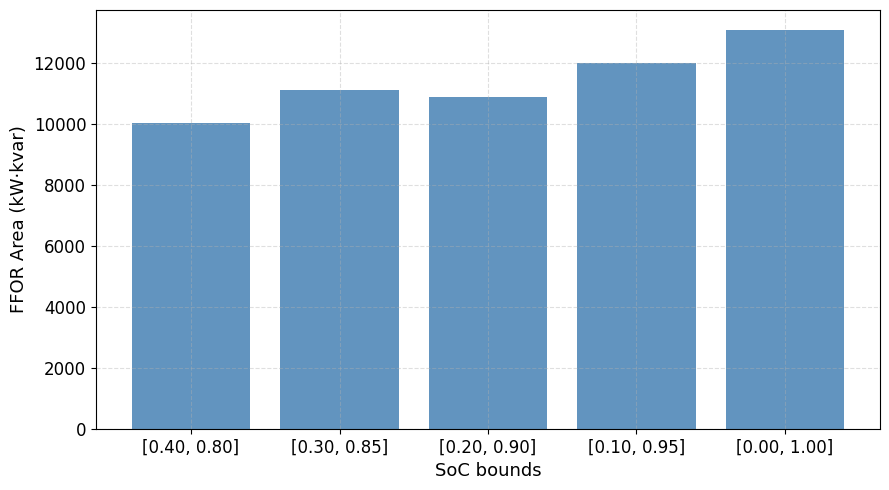

In [18]:
# ─────────────────────────────────────────────────────────────
# Plot FFOR area comparison
# ─────────────────────────────────────────────────────────────

labels = [
    f"[{r['SoC_min']:.2f}, {r['SoC_max']:.2f}]"
    for r in scenario_results
]

areas = [
    r['Area']
    for r in scenario_results
]

plt.figure(figsize=(9,5))

plt.bar(
    labels,
    areas,
    color='steelblue',
    alpha=0.85
)

plt.xlabel('SoC bounds', fontsize=13)
plt.ylabel('FFOR Area (kW·kvar)', fontsize=13)

plt.title('')

# Axe Y commence à 25000
# plt.ylim(bottom=25000)

plt.grid(
    True,
    linestyle='--',
    alpha=0.4
)

plt.xticks(
    rotation=0,
    fontsize=12
)

plt.yticks(
    rotation=0,
    fontsize=12
)

plt.tight_layout()

plt.savefig('ffor_area_soc_bounds.png', dpi=150, bbox_inches='tight')
plt.show()

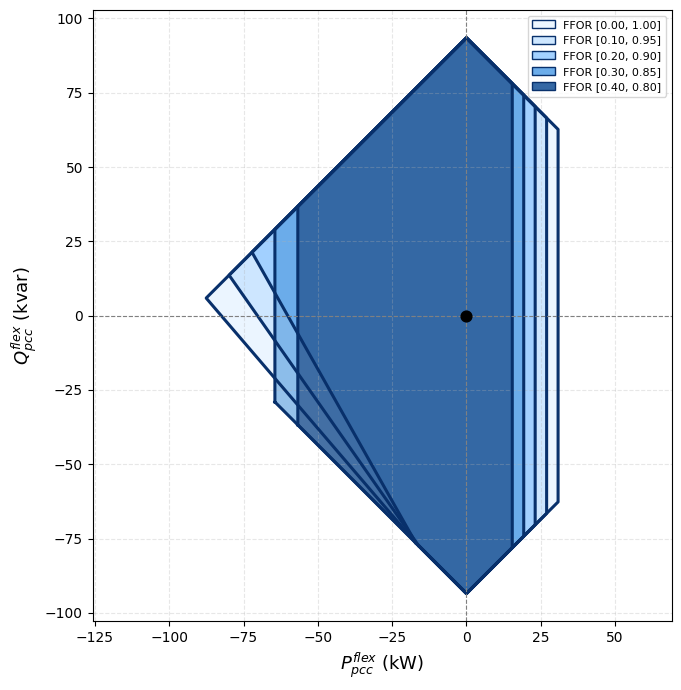

In [19]:
import matplotlib.colors as mcolors
import numpy as np
from matplotlib.patches import Patch

def blend(color, bg, alpha):
    """Mélange color sur bg avec alpha."""
    r, g, b = mcolors.to_rgb(color) if isinstance(color, str) else color
    br, bg_, bb = bg
    return (alpha*r + (1-alpha)*br, alpha*g + (1-alpha)*bg_, alpha*b + (1-alpha)*bb)

fig, ax = plt.subplots(figsize=(7, 7))

fill_colors = [
    '#dceeff',
    '#b6dbff',
    '#7fbfff',
    '#3f8fd9',
    '#08306b'
]
edge_color = '#08306b'
alpha = 0.55
bg_white = (1, 1, 1)
legend_patches = []

# On accumule le fond au fur et à mesure des superpositions
# reversed_results : le plus grand polygone dessiné en premier
reversed_results = scenario_results[::-1]

# Simuler l'accumulation des couches pour chaque polygone visible
# À chaque étape, la couleur vue = blend des couches précédentes
cumulative_bg = bg_white

# Calculer la couleur visuelle de chaque couche dans l'ordre de dessin
layer_colors = []
temp_bg = bg_white
for idx in range(len(reversed_results)):
    fc = fill_colors[idx]  # couleur de cette couche
    visible = blend(fc, temp_bg, alpha)
    layer_colors.append(visible)
    temp_bg = visible  # le fond suivant est ce qu'on voit maintenant

# Dessiner les polygones
for idx, r in enumerate(reversed_results):
    verts = r['Vertices']
    P = [v[0] for v in verts]
    Q = [v[1] for v in verts]
    P.append(verts[0][0])
    Q.append(verts[0][1])
    soc_min = r['SoC_min']
    soc_max = r['SoC_max']
    label = f"FFOR [{soc_min:.2f}, {soc_max:.2f}]"

    ax.fill(P, Q, color=fill_colors[idx], alpha=alpha, zorder=1)
    ax.plot(P, Q, color=edge_color, lw=2.2, zorder=2)

# Légende dans l'ordre naturel [0,1] → [0.4,0.8]
# layer_colors[0] = couleur vue du grand polygone (seul)
# layer_colors[1] = couleur vue de la 2e couche par-dessus, etc.
# Mais dans la légende on veut la couleur de chaque région visible
# region 0 = zone exclusive du polygone 0 = layer_colors[0]
# region 1 = zone exclusive du polygone 1 = layer_colors[1]
# ...
for idx, r in enumerate(scenario_results):  # ordre normal
    soc_min = r['SoC_min']
    soc_max = r['SoC_max']
    label = f"FFOR [{soc_min:.2f}, {soc_max:.2f}]"
    # reversed : layer_colors[0] = plus grand, layer_colors[-1] = plus petit
    layer_idx = len(scenario_results) - 1 - idx
    legend_patches.append(
        Patch(facecolor=layer_colors[layer_idx], edgecolor=edge_color, label=label)
    )

ax.scatter(0, 0, color='black', zorder=5, s=60)
ax.axhline(0, color='grey', lw=0.8, ls='--')
ax.axvline(0, color='grey', lw=0.8, ls='--')

ax.set_xlabel(r'$P_{pcc}^{flex}$ (kW)', fontsize=13)
ax.set_ylabel(r'$Q_{pcc}^{flex}$ (kvar)', fontsize=13)
ax.set_title('', fontsize=14)

legend_patches = legend_patches[::-1]
ax.legend(handles=legend_patches, fontsize=8, loc='best')
ax.set_aspect('equal', adjustable='datalim')
ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.savefig('ffor_soc_bounds.png', dpi=150, bbox_inches='tight')
plt.show()

In [20]:
#restore baseline SoC bounds after Scenario 1 sweep for next 2 scenarios
SoC_min = 0.4
SoC_max = 0.8
print(f'SoC bounds restored: [{SoC_min}, {SoC_max}]')

SoC bounds restored: [0.4, 0.8]


## 8 — Scenario 3: Inverter Power Limit Scaling

The nominal inverter power rating of each BESS is scaled up uniformly by factors
of 1×, 1.5×, 2×, 3×, and 4× relative to the baseline. This represents a hardware
investment in higher-power inverters, enabling faster charge and discharge rates.
The FFOR is recomputed at each scaling factor to quantify the flexibility gain
from increasing the power limit constraint.

In [21]:
def compute_ffor_area():
    v1, _ = solve_ffor_direction(+1,  0, silent=True)
    v2, _ = solve_ffor_direction( 0, +1, silent=True)
    v3, _ = solve_ffor_direction(-1,  0, silent=True)
    v4, _ = solve_ffor_direction( 0, -1, silent=True)

    verts = list(sort_vertices_ccw(unique_vertices([v1, v2, v3, v4])))
    edges = deque([(i, (i+1) % len(verts)) for i in range(len(verts))])

    while edges:
        i, j     = edges.popleft()
        vi, vj   = verts[i], verts[j]
        alpha, beta = edge_normal_direction(vi, vj)
        result   = solve_ffor_direction(alpha, beta, silent=True)
        if result is None:
            continue
        v_new, _ = result
        delta_A  = triangle_area(vi, v_new, vj)
        if delta_A > epsilon_tol:
            if not any(np.hypot(v_new[0]-v[0], v_new[1]-v[1]) < 1e-6 for v in verts):
                new_idx = len(verts)
                verts.append(v_new)
                edges.append((i, new_idx))
                edges.append((new_idx, j))

    verts = sort_vertices_ccw(verts)
    return polygon_area(verts), verts

In [22]:
# Chnage in FFOR when all BESS inverters scaled the same
power_scale_factors = [1.0, 1.5, 2.0, 3.0, 4.0, 6.0, 8.0, 10.0]
P_nom_orig = {s: P_nom[s] for s in S}
scenario3_results = []

for scale in power_scale_factors:
    for s in S:
        P_nom[s] = P_nom_orig[s] * scale

    v1, _ = solve_ffor_direction(+1,  0, silent=True)
    v2, _ = solve_ffor_direction( 0, +1, silent=True)
    v3, _ = solve_ffor_direction(-1,  0, silent=True)
    v4, _ = solve_ffor_direction( 0, -1, silent=True)

    verts = list(sort_vertices_ccw(unique_vertices([v1, v2, v3, v4])))
    edges = deque([(i, (i+1) % len(verts)) for i in range(len(verts))])

    while edges:
        i, j = edges.popleft()
        vi, vj = verts[i], verts[j]
        alpha, beta = edge_normal_direction(vi, vj)
        result = solve_ffor_direction(alpha, beta, silent=True)
        if result is None:
            continue
        v_new, _ = result
        if triangle_area(vi, v_new, vj) > epsilon_tol:
            if not any(np.hypot(v_new[0]-v[0], v_new[1]-v[1]) < 1e-6 for v in verts):
                new_idx = len(verts)
                verts.append(v_new)
                edges.append((i, new_idx))
                edges.append((new_idx, j))

    verts = sort_vertices_ccw(verts)
    area  = polygon_area(verts)
    scenario3_results.append({'scale': scale, 'P_nom': {s: P_nom[s] for s in S},
                               'Area': area, 'Vertices': verts})
    print(f"scale={scale:.1f}x | Area={area:.0f} kW·kvar")

for s in S:
    P_nom[s] = P_nom_orig[s]

scale=1.0x | Area=10032 kW·kvar
scale=1.5x | Area=14037 kW·kvar
scale=2.0x | Area=17719 kW·kvar
scale=3.0x | Area=24131 kW·kvar
scale=4.0x | Area=29065 kW·kvar
scale=6.0x | Area=34899 kW·kvar
scale=8.0x | Area=38814 kW·kvar
scale=10.0x | Area=41554 kW·kvar


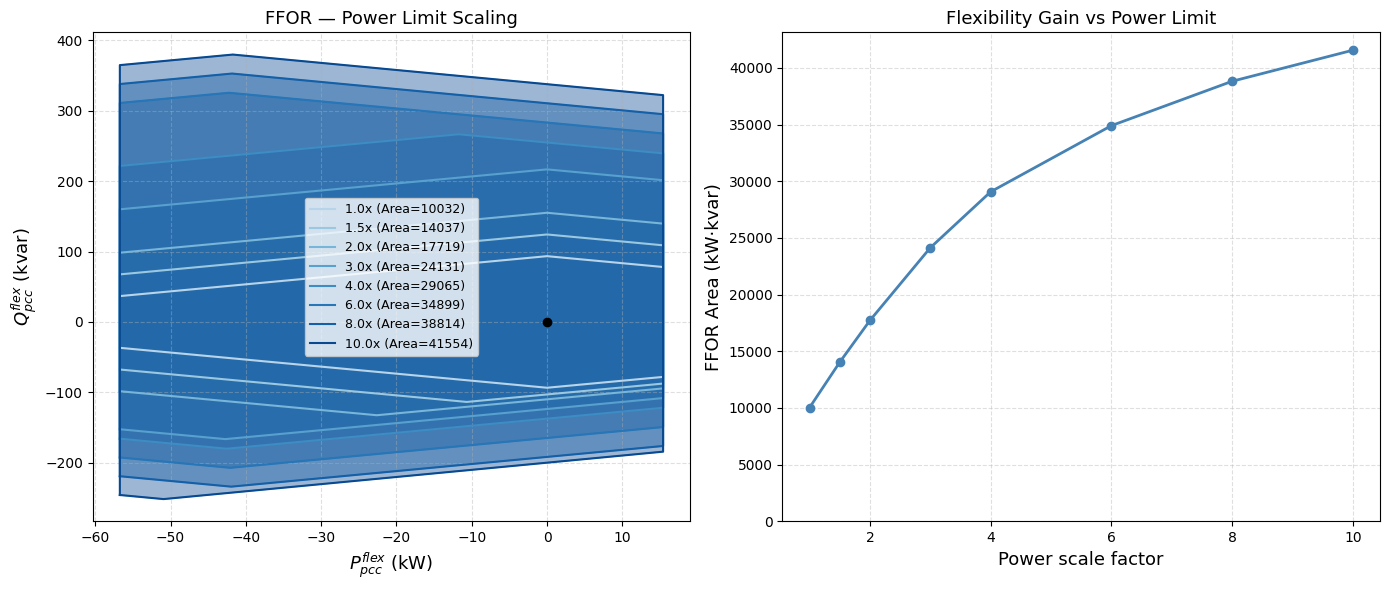

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ── Left: FFOR shapes ──
ax = axes[0]
colors = plt.cm.Blues(np.linspace(0.3, 0.9, len(scenario3_results)))

for r, color in zip(scenario3_results, colors):
    verts = r['Vertices'] + [r['Vertices'][0]]
    P = [v[0] for v in verts]
    Q = [v[1] for v in verts]
    ax.fill(P, Q, alpha=0.4, color=color)
    ax.plot(P, Q, color=color, linewidth=1.5,
            label=f"{r['scale']:.1f}x (Area={r['Area']:.0f})")

ax.scatter([0], [0], color='black', zorder=5)
ax.set_xlabel(r'$P_{pcc}^{flex}$ (kW)', fontsize=13)
ax.set_ylabel(r'$Q_{pcc}^{flex}$ (kvar)', fontsize=13)
ax.set_title('FFOR — Power Limit Scaling', fontsize=13)
ax.legend(fontsize=9)
ax.grid(True, linestyle='--', alpha=0.4)

# ── Right: Area vs scale factor ──
ax2 = axes[1]
scales = [r['scale'] for r in scenario3_results]
areas  = [r['Area']  for r in scenario3_results]

ax2.plot(scales, areas, marker='o', color='steelblue', linewidth=2)
ax2.set_xlabel('Power scale factor', fontsize=13)
ax2.set_ylabel('FFOR Area (kW·kvar)', fontsize=13)
ax2.set_title('Flexibility Gain vs Power Limit', fontsize=13)
ax2.grid(True, linestyle='--', alpha=0.4)
ax2.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

In [24]:
# check what takes over when inverter saturates
# ── Dual tracking across scale factors ──
dual_tracking = {
    'scale':       [],
    'SoC_bounds':  {'max_P': [], 'max_Q': [], 'min_P': [], 'min_Q': []},
    'BESS_power':  {'max_P': [], 'max_Q': [], 'min_P': [], 'min_Q': []},
    'voltage':     {'max_P': [], 'max_Q': [], 'min_P': [], 'min_Q': []},
    'sustained':   {'max_P': [], 'max_Q': [], 'min_P': [], 'min_Q': []},
    'PV_power':    {'max_P': [], 'max_Q': [], 'min_P': [], 'min_Q': []},
    'line_limits': {'max_P': [], 'max_Q': [], 'min_P': [], 'min_Q': []},
}

directions = [(+1, 0, 'max_P'), (0, +1, 'max_Q'), (-1, 0, 'min_P'), (0, -1, 'min_Q')]

power_scale_factors_extended = [1.0, 1.5, 2.0, 3.0, 4.0, 6.0, 8.0, 10.0]

for scale in power_scale_factors_extended:
    for s in S:
        P_nom[s] = P_nom_orig[s] * scale

    dual_tracking['scale'].append(scale)

    for alpha, beta, label in directions:
        result = solve_ffor_direction(alpha, beta, silent=True)
        if result is None:
            # Fill with NaN if infeasible
            for cat in ['SoC_bounds', 'BESS_power', 'voltage',
                        'sustained', 'PV_power', 'line_limits']:
                dual_tracking[cat][label].append(float('nan'))
            continue

        point, duals = result

        # Reuse your categorisation logic from summarise_duals
        cat_vals = {cat: [] for cat in dual_tracking if cat != 'scale'}
        for name, pi in duals.items():
            if   'SoC' in name or 'C03' in name:    cat_vals['SoC_bounds'].append(abs(pi))
            elif 'C15_line'      in name:            cat_vals['line_limits'].append(abs(pi))
            elif 'C16_voltage'   in name:            cat_vals['voltage'].append(abs(pi))
            elif 'C19_sustained' in name or 'C20_sustained' in name:
                                                     cat_vals['sustained'].append(abs(pi))
            elif 'C04_BESS'      in name:            cat_vals['BESS_power'].append(abs(pi))
            elif 'C07_PV'        in name or 'C08_PV' in name:
                                                     cat_vals['PV_power'].append(abs(pi))

        for cat in cat_vals:
            val = max(cat_vals[cat]) if cat_vals[cat] else 0.0
            dual_tracking[cat][label].append(val)

# Restore
for s in S:
    P_nom[s] = P_nom_orig[s]

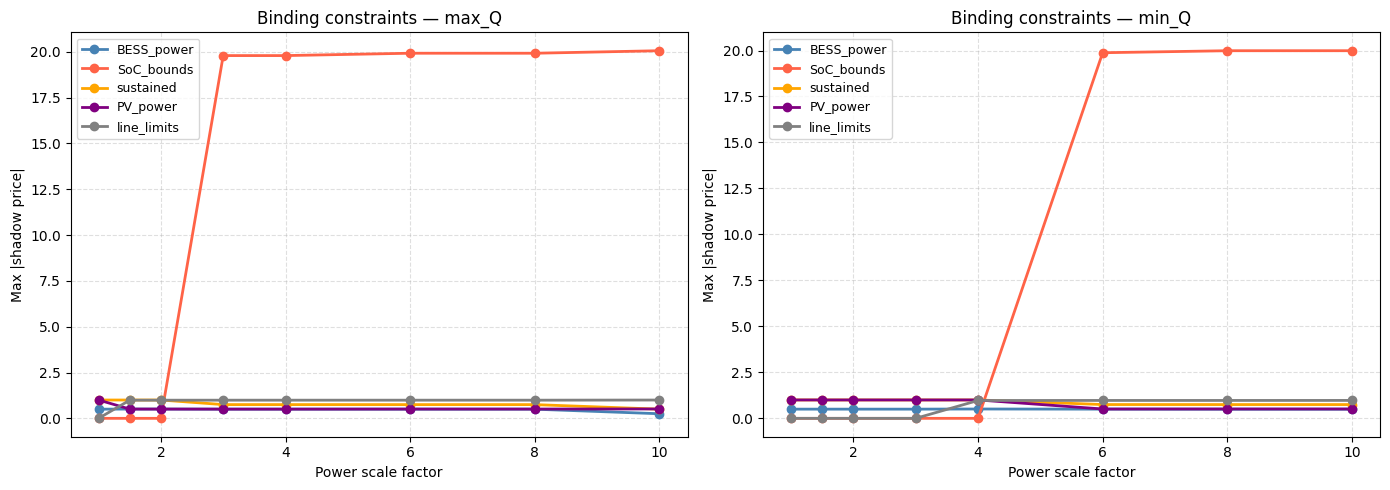

In [25]:
# plot for report
scales = dual_tracking['scale']

# One figure per direction, or pick the two most informative (max_Q and min_Q)
# since that's where BESS_power was binding
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, label in zip(axes, ['max_Q', 'min_Q']):
    for cat, color in [('BESS_power',  'steelblue'),
                       ('SoC_bounds',  'tomato'),
                       ('voltage',     'green'),
                       ('sustained',   'orange'),
                       ('PV_power',    'purple'),
                       ('line_limits', 'grey')]:
        vals = dual_tracking[cat][label]
        if any(v > 0 for v in vals):          # only plot if ever active
            ax.plot(scales, vals, marker='o', label=cat, color=color, linewidth=2)

    ax.set_xlabel('Power scale factor')
    ax.set_ylabel('Max |shadow price|')
    ax.set_title(f'Binding constraints — {label}')
    ax.legend(fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

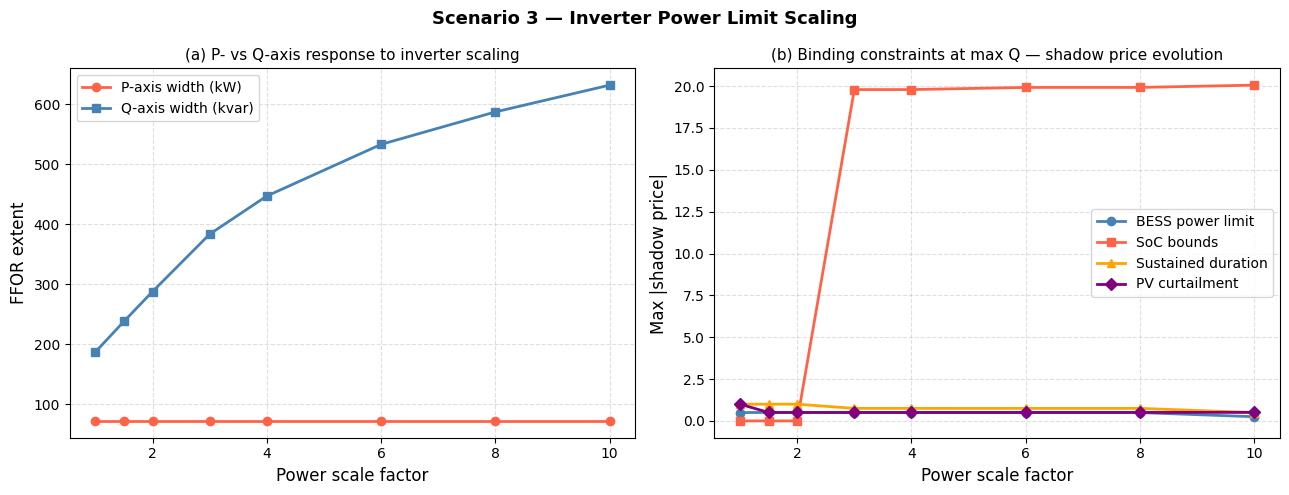

In [26]:
# plot for report 
scales   = [r['scale'] for r in scenario3_results]
P_widths = [max(v[0] for v in r['Vertices']) - min(v[0] for v in r['Vertices'])
            for r in scenario3_results]
Q_widths = [max(v[1] for v in r['Vertices']) - min(v[1] for v in r['Vertices'])
            for r in scenario3_results]

dual_scales = dual_tracking['scale']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ── Left: P/Q width ──
ax = axes[0]
ax.plot(scales, P_widths, marker='o', color='tomato',    linewidth=2,
        label='P-axis width (kW)')
ax.plot(scales, Q_widths, marker='s', color='steelblue', linewidth=2,
        label='Q-axis width (kvar)')
ax.set_xlabel('Power scale factor', fontsize=12)
ax.set_ylabel('FFOR extent', fontsize=12)
ax.set_title('(a) P- vs Q-axis response to inverter scaling', fontsize=11)
ax.legend(fontsize=10)
ax.grid(True, linestyle='--', alpha=0.4)

# ── Right: dual evolution at max_Q only ──
ax2 = axes[1]
cat_styles = [('BESS_power', 'steelblue', 'o', 'BESS power limit'),
              ('SoC_bounds', 'tomato',    's', 'SoC bounds'),
              ('sustained',  'orange',    '^', 'Sustained duration'),
              ('PV_power',   'purple',    'D', 'PV curtailment')]

for cat, color, marker, lbl in cat_styles:
    vals = dual_tracking[cat]['max_Q']
    if any(v > 0 for v in vals):
        ax2.plot(dual_scales, vals, marker=marker, color=color,
                 linewidth=2, label=lbl)

ax2.set_xlabel('Power scale factor', fontsize=12)
ax2.set_ylabel('Max |shadow price|', fontsize=12)
ax2.set_title('(b) Binding constraints at max Q — shadow price evolution', fontsize=11)
ax2.legend(fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.4)

plt.suptitle('Scenario 3 — Inverter Power Limit Scaling', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('FFOR_scenario3.png', dpi=150, bbox_inches='tight')
plt.show()

In [27]:
# individual BESS upgrade and ranking per scale factor 
scale_targets = [1.5, 2.0, 3.0, 4.0]

results_single_multiscale = {scale: [] for scale in scale_targets}

# ── BESS metadata for labelling ──
bess_info = {
    0: {'bus': 16, 'P_nom_orig': P_nom_orig[0]},
    1: {'bus': 33, 'P_nom_orig': P_nom_orig[1]},
    2: {'bus': 32, 'P_nom_orig': P_nom_orig[2]},
    3: {'bus': 41, 'P_nom_orig': P_nom_orig[3]},
    4: {'bus': 62, 'P_nom_orig': P_nom_orig[4]},
    5: {'bus': 36, 'P_nom_orig': P_nom_orig[5]},
}

for scale_target in scale_targets:
    print(f"\n{'='*60}")
    print(f"Scale factor = {scale_target:.1f}x")
    print(f"{'='*60}")

    for s_upgrade in S:
        # Upgrade only this one BESS
        for s in S:
            P_nom[s] = P_nom_orig[s] * (scale_target if s == s_upgrade else 1.0)

        area, verts = compute_ffor_area()

        delta_area    = area - ffor_area
        delta_P_nom   = P_nom_orig[s_upgrade] * (scale_target - 1)  # added kW
        gain_per_kW   = delta_area / delta_P_nom                     # kW·kvar per kW added
        Q_width       = max(v[1] for v in verts) - min(v[1] for v in verts)

        results_single_multiscale[scale_target].append({
            'BESS':           s_upgrade,
            'bus':            bess_info[s_upgrade]['bus'],
            'P_nom_orig_kW':  P_nom_orig[s_upgrade],
            'Area':           area,
            'Delta_Area':     delta_area,
            'Delta_Area_pct': 100 * delta_area / ffor_area,
            'Q_width':        Q_width,
            'Delta_P_nom':    delta_P_nom,
            'Gain_per_kW':    gain_per_kW,
        })

    # Restore after each scale
    for s in S:
        P_nom[s] = P_nom_orig[s]

    # ── Print ranked table for this scale ──
    ranked = sorted(results_single_multiscale[scale_target],
                    key=lambda x: x['Gain_per_kW'], reverse=True)
    print(f"\n  {'Rank':<5} {'BESS':<6} {'bus':<6} {'P_orig(kW)':<12} "
          f"{'ΔArea':>10} {'ΔArea%':>8} {'ΔP_nom(kW)':>12} {'Gain/kW':>10}")
    print(f"  {'-'*75}")
    for rank, r in enumerate(ranked, 1):
        print(f"  {rank:<5} {r['BESS']:<6} {r['bus']:<6} "
              f"{r['P_nom_orig_kW']:<12.1f} "
              f"{r['Delta_Area']:>10.0f} "
              f"{r['Delta_Area_pct']:>7.1f}% "
              f"{r['Delta_P_nom']:>12.1f} "
              f"{r['Gain_per_kW']:>10.3f}")


Scale factor = 1.5x

  Rank  BESS   bus    P_orig(kW)        ΔArea   ΔArea%   ΔP_nom(kW)    Gain/kW
  ---------------------------------------------------------------------------
  1     2      32     4.1                 293     2.9%          2.0    144.297
  2     4      62     13.3                961     9.6%          6.7    144.297
  3     1      33     6.7                 469     4.7%          3.3    140.924
  4     3      41     8.1                 562     5.6%          4.0    138.733
  5     0      16     13.8                925     9.2%          6.9    134.097
  6     5      36     15.7               1047    10.4%          7.9    133.243

Scale factor = 2.0x

  Rank  BESS   bus    P_orig(kW)        ΔArea   ΔArea%   ΔP_nom(kW)    Gain/kW
  ---------------------------------------------------------------------------
  1     4      62     13.3               1922    19.2%         13.3    144.297
  2     2      32     4.1                 562     5.6%          4.1    138.706
  3     1 

## 9 — Scenario 2: Battery Capacity Scaling

Adding more battery capacity helps flexibility, but only up to the point where the inverter's power rating becomes the new bottleneck. The two are related via $0.1 \cdot C_s = P_{\text{nom}}$. Since we know $P_{\text{nom}}$ for each BESS, one observes that scaling up to **4×** is possible, while beyond that, bigger inverters would be needed (see Scenario 3) to further increase the maximum sustained discharge:

$$
P_{\max}^{\text{sustained}} = \min\!\left(0.1 \cdot C_s,\; P_{\text{nom}}\right)
$$

As a result, the energy capacity of each BESS is scaled up uniformly by factors of **1×, 1.5×, 2×, 3×, 4×, 5x and 6x** relative to the baseline. The **5x and 6x** show that the inverter's power rating becomes the bottleneck.  This represents a hardware investment in larger battery packs, allowing the battery to keep providing power for a longer time before reaching its SoC bounds.

### Derivation

Recall the SoC dynamics constraint:

$$
\mathrm{SoC}[t+1] = \mathrm{SoC}[t] - \frac{h}{C_s} \cdot P_b[t]
$$

Apply it across the FFOR window ($T = 3$, so 2 transitions). Assume the battery dispatches at constant power $P_b = P$ for all 3 hours:

$$
\begin{aligned}
\mathrm{SoC}[0] &= 0.6 && \text{(initial)} \\
\mathrm{SoC}[1] &= 0.6 - \tfrac{h}{C_s} \cdot P && \text{(after hour 1)} \\
\mathrm{SoC}[2] &= 0.6 - 2 \cdot \tfrac{h}{C_s} \cdot P && \text{(after hour 2)}
\end{aligned}
$$

The constraint $\mathrm{SoC} \geq \mathrm{SoC}_{\min} = 0.4$ must hold at every timestep. The lowest SoC occurs at $t=2$:

$$
\begin{aligned}
\mathrm{SoC}[2] &\geq \mathrm{SoC}_{\min} \\
0.6 - 2 \cdot \tfrac{h}{C_s} \cdot P &\geq 0.4 \\
0.2 &\geq 2 \cdot \tfrac{h}{C_s} \cdot P \\
P &\leq \frac{0.2 \cdot C_s}{2 \cdot h} \\
P &\leq 0.1 \cdot C_s \quad \text{(with } h=1\text{)}
\end{aligned}
$$

So the maximum sustained $P$ that doesn't violate SoC bounds is $0.1 \cdot C_s$. There is also a separate upper limit from the inverter rating (constraint C04):

$$
P \leq P_{\text{nom}}
$$

### Example: BESS 0

- $P_{\text{nom}} = 13.8$ kW (inverter ceiling)
- $C_s^{\text{baseline}} = 34.5$ kWh

| Multiplier | $C_s$ (kWh) | Sustained $P$ (kW) | Regime |
|:---:|:---:|:---:|:---|
| 1× | 34.5  | $0.1 \times 34.5 = 3.45$  | energy-limited |
| 2× | 69    | $0.1 \times 69 = 6.90$    | energy-limited |
| 3× | 103.5 | $0.1 \times 103.5 = 10.35$ | energy-limited |
| 4× | 138   | $0.1 \times 138 = 13.80$  | **at the ceiling** |
| 5× | 172.5 | $\min(17.25,\, 13.8) = 13.80$ | **power-limited** |

In [28]:
# Scenario 2 — Battery capacity scaling 
# ─────────────────────────────────────────────────────────────
# Multiplies all BESS energy capacities by a factor and recomputes FFOR
# Larger C_s --> smaller SoC drop per kW (since: SoC[s, t+1] = SoC[s, t] - (h / C_s[s]) * Pb[s, t]) --> more sustained active power dispatch w.o. violating SoC bounds
# Q-axis should be largely unchanged since reactive doesn't drain SoC.


#map each BESS to its energy capacity  & save for comparison 
C_s_baseline = dict(C_s) 

#compute FFOR like in Cell 18, to be called for diffrent the 5 scalings 
def run_ffor_polygon():
    
    v1, _ = solve_ffor_direction(+1,  0, silent=True)
    v2, _ = solve_ffor_direction( 0, +1, silent=True)
    v3, _ = solve_ffor_direction(-1,  0, silent=True)
    v4, _ = solve_ffor_direction( 0, -1, silent=True)

    verts = sort_vertices_ccw(unique_vertices([v1, v2, v3, v4]))
    if len(verts) < 3:
        raise RuntimeError('Less than 3 initial vertices')

    edges = deque([(i, (i+1) % len(verts)) for i in range(len(verts))])
    n_solves = 4

    while edges:
        i, j = edges.popleft()
        a, b = edge_normal_direction(verts[i], verts[j])
        res, _ = solve_ffor_direction(a, b, silent=True)
        n_solves += 1
        if res is None:
            continue
        if triangle_area(verts[i], res, verts[j]) > epsilon_tol:
            if any(np.hypot(res[0]-v[0], res[1]-v[1]) < 1e-6 for v in verts):
                continue
            new_idx = len(verts)
            verts.append(res)
            edges.append((i, new_idx))
            edges.append((new_idx, j))

    verts = sort_vertices_ccw(verts)
    P = np.array([v[0] for v in verts] + [verts[0][0]])
    Q = np.array([v[1] for v in verts] + [verts[0][1]])
    area = 0.5 * abs(np.dot(P[:-1], Q[1:]) - np.dot(Q[:-1], P[1:]))

    return {'vertices': verts, 'P': P, 'Q': Q, 'area': area, 'n_solves': n_solves}
    
#add & print for sanity check 
print(f'Baseline C_s saved: total = {sum(C_s_baseline.values()):.2f} kWh')

Baseline C_s saved: total = 154.11 kWh


In [29]:
capacity_multipliers = [1.0, 1.5, 2.0, 3.0, 4.0, 5.0, 6.0]
scenario_2_results = []

#iterate over the 5 capacity_multipliers and scale C_s[s] 
for mult in capacity_multipliers:
    print(f'\n── C_s × {mult} ──')
    #each BESS' initial capacity is multiplied with the capacity_multipliers of the current iteration
    for s in S:
        C_s[s] = C_s_baseline[s] * mult
    
    # Compute FFOR of the current iteration & save its result
    r = run_ffor_polygon()
    r['multiplier'] = mult
    scenario_2_results.append(r)

    #print the FFOR polygon at the PCC for each of the capacity_multipliers
    print(f'  Area: {r["area"]:.1f} | P=[{r["P"].min():.2f}, {r["P"].max():.2f}] '
          f'| Q=[{r["Q"].min():.2f}, {r["Q"].max():.2f}]')

# Restore baseline so the rest of the notebook is unaffected
for s in S:
    C_s[s] = C_s_baseline[s]
print(f'\nBaseline C_s restored.')


── C_s × 1.0 ──
  Area: 10032.3 | P=[-56.74, 15.41] | Q=[-93.48, 93.48]

── C_s × 1.5 ──
  Area: 11682.9 | P=[-64.44, 23.12] | Q=[-93.48, 93.48]

── C_s × 2.0 ──
  Area: 11901.4 | P=[-72.15, 30.82] | Q=[-93.48, 93.48]

── C_s × 3.0 ──
  Area: 14787.0 | P=[-87.56, 46.23] | Q=[-93.48, 93.48]

── C_s × 4.0 ──
  Area: 16463.6 | P=[-93.48, 61.65] | Q=[-93.48, 93.48]

── C_s × 5.0 ──
  Area: 16463.6 | P=[-93.48, 61.65] | Q=[-93.48, 93.48]

── C_s × 6.0 ──
  Area: 16463.6 | P=[-93.48, 61.65] | Q=[-93.48, 93.48]

Baseline C_s restored.


In [30]:

# Summary table comparing the multiplier scenarios
results_df = pd.DataFrame([
    {
        'C_s ×': r['multiplier'],
        'Total C_s (kWh)': round(sum(C_s_baseline.values()) * r['multiplier'], 1),
        'Area (kW·kvar)':  round(r['area'], 1),
        'P_min':           round(r['P'].min(), 2),
        'P_max':           round(r['P'].max(), 2),
        'Q_min':           round(r['Q'].min(), 2),
        'Q_max':           round(r['Q'].max(), 2),
        'Area gain %':     round((r['area']/scenario_2_results[0]['area'] - 1)*100, 1),
    }
    for r in scenario_2_results
])
print(results_df.to_string(index=False))

 C_s ×  Total C_s (kWh)  Area (kW·kvar)  P_min  P_max  Q_min  Q_max  Area gain %
   1.0            154.1         10032.3 -56.74  15.41 -93.48  93.48          0.0
   1.5            231.2         11682.9 -64.44  23.12 -93.48  93.48         16.5
   2.0            308.2         11901.4 -72.15  30.82 -93.48  93.48         18.6
   3.0            462.3         14787.0 -87.56  46.23 -93.48  93.48         47.4
   4.0            616.5         16463.6 -93.48  61.65 -93.48  93.48         64.1
   5.0            770.6         16463.6 -93.48  61.65 -93.48  93.48         64.1
   6.0            924.7         16463.6 -93.48  61.65 -93.48  93.48         64.1


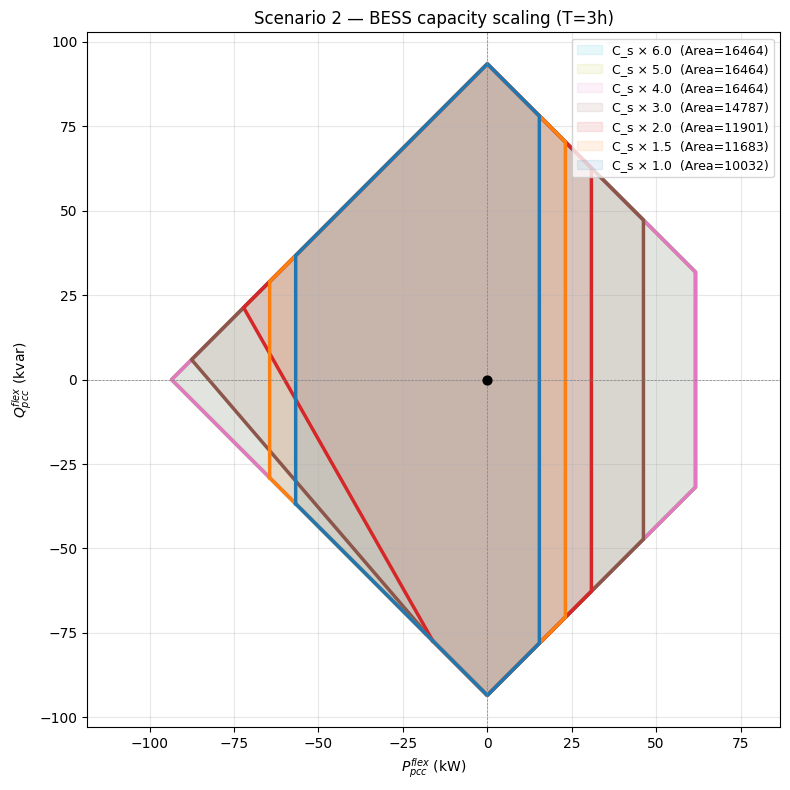

In [31]:

#plot the FFOR for diffrent capacity_multipliers
import matplotlib.colors as mcolors

fig, ax = plt.subplots(figsize=(8, 8))

# Distinct color per multiplier (qualitative palette)
colors_list = plt.cm.tab10(np.linspace(0, 1, len(capacity_multipliers)))
color_map = {mult: colors_list[i] for i, mult in enumerate(capacity_multipliers)}

for r in sorted(scenario_2_results, key=lambda x: -x['multiplier']):
    color = color_map[r['multiplier']]
    ax.fill(r['P'], r['Q'], alpha=0.10, color=color,
            label=f"C_s × {r['multiplier']}  (Area={r['area']:.0f})")
    ax.plot(r['P'], r['Q'], color=color, lw=2.5)

ax.scatter(0, 0, color='black', s=40, zorder=10)
ax.axhline(0, color='grey', lw=0.5, ls='--')
ax.axvline(0, color='grey', lw=0.5, ls='--')
ax.set_xlabel(r'$P_{pcc}^{flex}$ (kW)')
ax.set_ylabel(r'$Q_{pcc}^{flex}$ (kvar)')
ax.set_title(f'Scenario 2 — BESS capacity scaling (T={T}h)')
ax.legend(fontsize=9, loc='upper right')
ax.set_aspect('equal', adjustable='datalim')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('FFOR_scenario2.png', dpi=150, bbox_inches='tight')
plt.show()

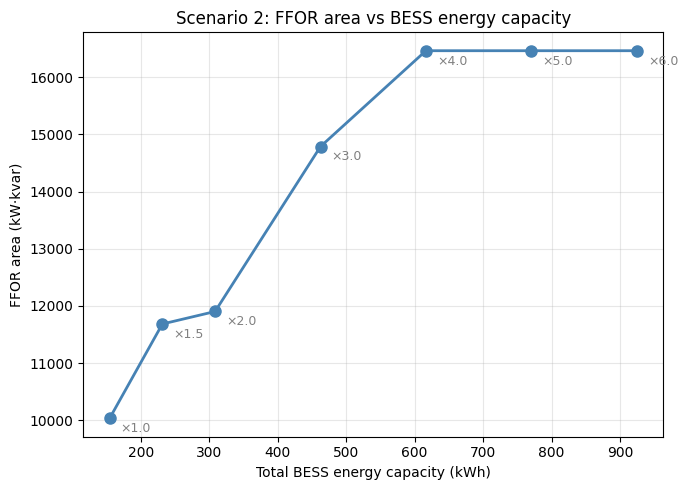


Growth between consecutive capacity levels:
  1.0 → 1.5 (C_s = 154 → 231 kWh): area grew by +16.5%
  1.5 → 2.0 (C_s = 231 → 308 kWh): area grew by +1.9%
  2.0 → 3.0 (C_s = 308 → 462 kWh): area grew by +24.2%
  3.0 → 4.0 (C_s = 462 → 616 kWh): area grew by +11.3%
  4.0 → 5.0 (C_s = 616 → 771 kWh): area grew by +0.0%
  5.0 → 6.0 (C_s = 771 → 925 kWh): area grew by +0.0%


In [32]:
plt.figure(figsize=(7, 5))

# Convert multipliers to absolute total capacity (kWh)
total_caps = [sum(C_s_baseline.values()) * r['multiplier'] for r in scenario_2_results]
mults = [r['multiplier'] for r in scenario_2_results]
areas = [r['area'] for r in scenario_2_results]

plt.plot(total_caps, areas, 'o-', lw=2, ms=8, color='steelblue')

# Annotate each point with its multiplier (so both interpretations are visible)
for cap, area, mult in zip(total_caps, areas, mults):
    plt.annotate(f'×{mult}', (cap, area), textcoords='offset points',
                 xytext=(8, -10), fontsize=9, color='grey')

plt.xlabel('Total BESS energy capacity (kWh)')
plt.ylabel('FFOR area (kW·kvar)')
plt.title('Scenario 2: FFOR area vs BESS energy capacity')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('FFOR_scenario2_area.png', dpi=150, bbox_inches='tight')
plt.show()

# Growth between consecutive multipliers
print('\nGrowth between consecutive capacity levels:')
for i in range(1, len(areas)):
    gain = (areas[i] - areas[i-1]) / areas[i-1] * 100
    print(f'  {mults[i-1]} → {mults[i]} (C_s = {total_caps[i-1]:.0f} → {total_caps[i]:.0f} kWh): area grew by {gain:+.1f}%')